## Imports

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split, cross_val_predict, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import missingno as msno
import seaborn as sns

In [143]:
def cMSE(y, y_hat, c):
    import numpy as np
    err = y-y_hat
    err = (1-c)*err**2 + c*np.maximum(0,err)**2
    return np.sum(err)/err.shape[0]
    
def plot_y_yhat(y_test, y_pred, plot_title="plot"):
    # Only one target variable: SurvivalTime
    label = 'SurvivalTime'
    MAX = 500

    # Select indices for plotting
    if len(y_test) > MAX:
        idx = np.random.choice(len(y_test), MAX, replace=False)
    else:
        idx = np.arange(len(y_test))

    # Plot True vs Predicted for SurvivalTime
    plt.figure(figsize=(6, 6))
    x0 = np.min(y_test[idx])
    x1 = np.max(y_test[idx])
    plt.scatter(y_test[idx], y_pred[idx], alpha=0.7)
    plt.xlabel(f'True {label}')
    plt.ylabel(f'Predicted {label}')
    plt.plot([x0, x1], [x0, x1], color='red')
    plt.title(f'True vs Predicted {label}')
    plt.axis('square')
    plt.savefig(plot_title + '.pdf')
    plt.show()

def save_predictions(predictions, path):
    df = pd.DataFrame(predictions, columns=['SurvivalTime'])
    df_survival = df[['SurvivalTime']]
    df_survival['id'] = df_survival.index
    df_survival = df_survival[['id', 'SurvivalTime']]
    df_survival.to_csv(path, index=False)
    
def save_predictions(predictions, path):
    # Create a DataFrame with the 'id' column and the predictions
    df = pd.DataFrame({
        'id': range(len(predictions)),
        '0': predictions
    })
    
    # Save the DataFrame to a CSV file
    df.to_csv(path, index=False)

In [151]:
df = pd.read_csv('./mlNOVA/train_data.csv')
df.drop(columns=['id'], inplace=True)
df.head()

,Age,Gender,Stage,GeneticRisk,TreatmentType,ComorbidityIndex,TreatmentResponse,SurvivalTime,Censored
0,65.0,0,2,1.0,0,0.0,0.0,4.2,0
1,68.0,1,2,0.0,1,1.0,1.0,4.7,1
2,68.0,1,3,1.0,1,0.0,1.0,3.5,1
3,81.0,1,4,1.0,1,3.0,0.0,2.3,0
4,59.0,1,2,1.0,0,NaN,0.0,NaN,0


<Axes: >

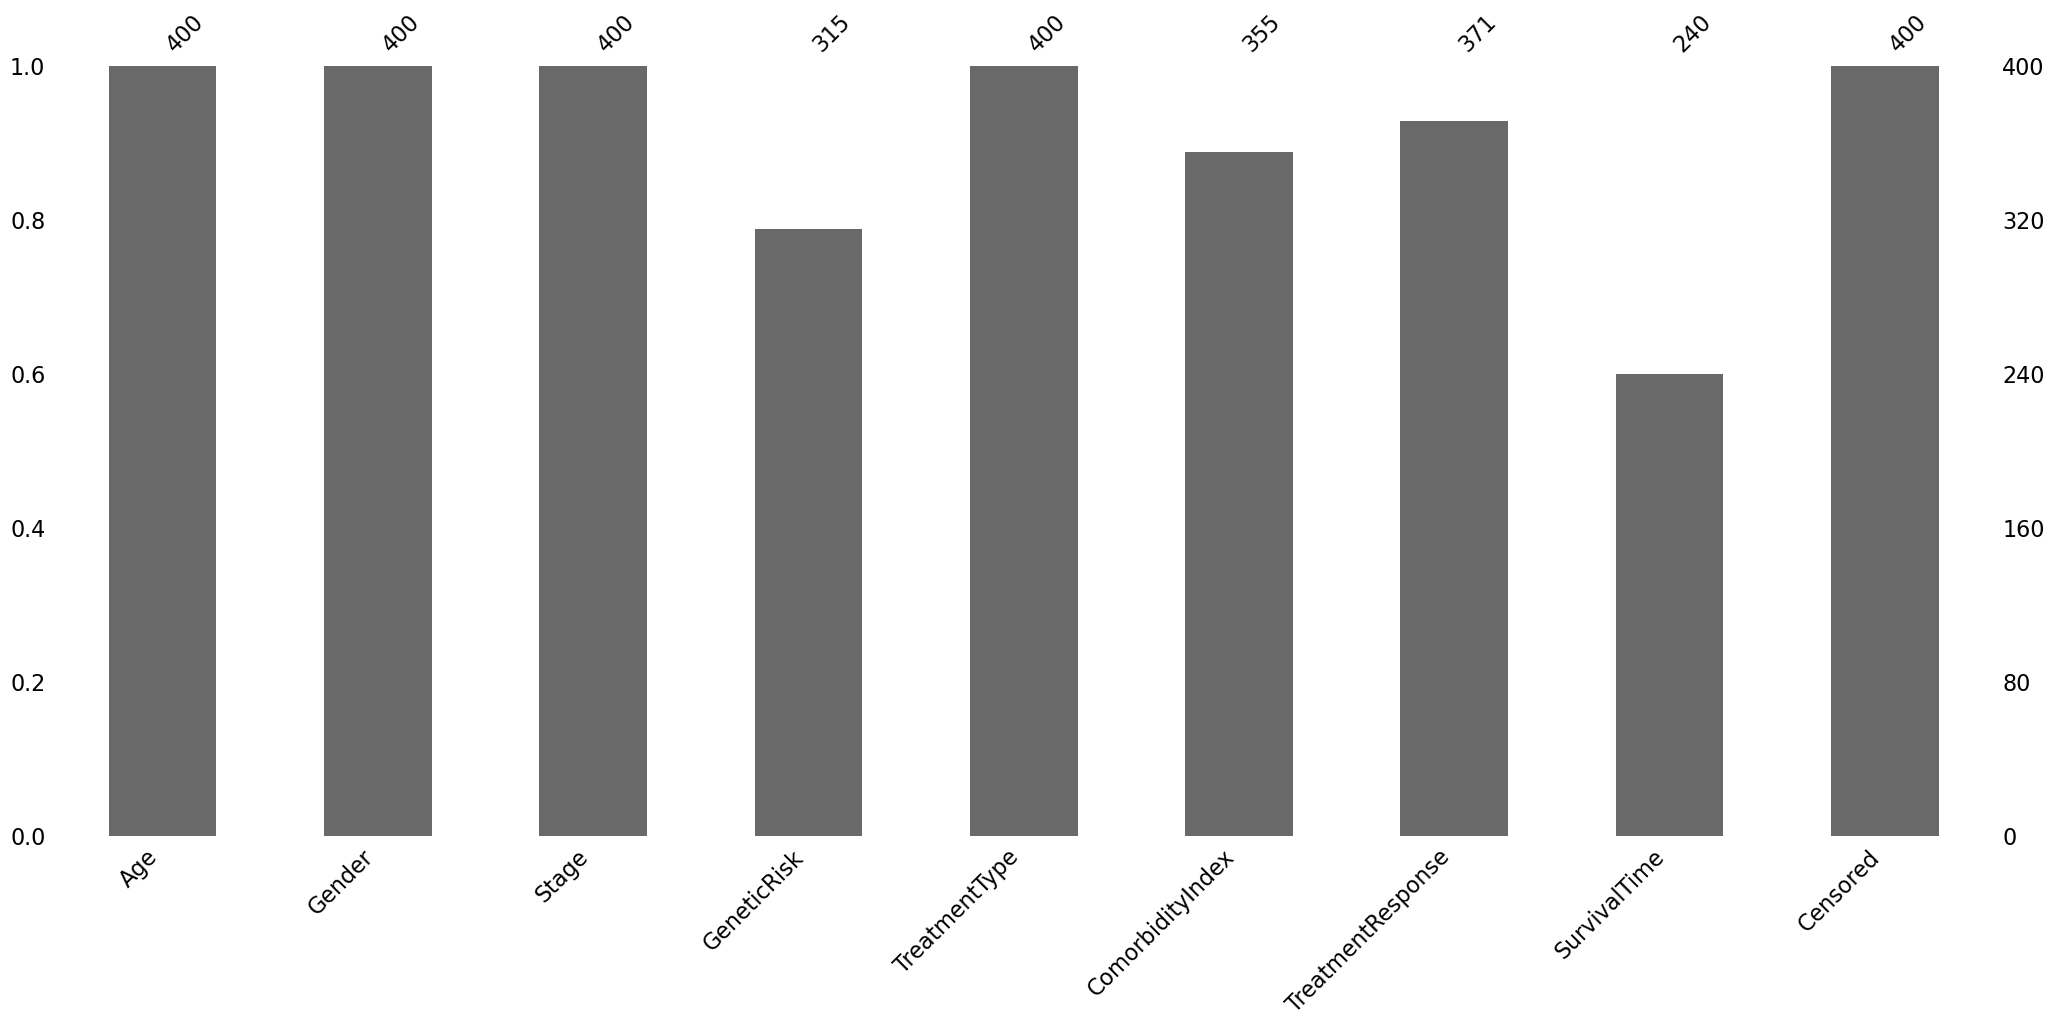

In [ ]:
msno.bar(df)

<Axes: >

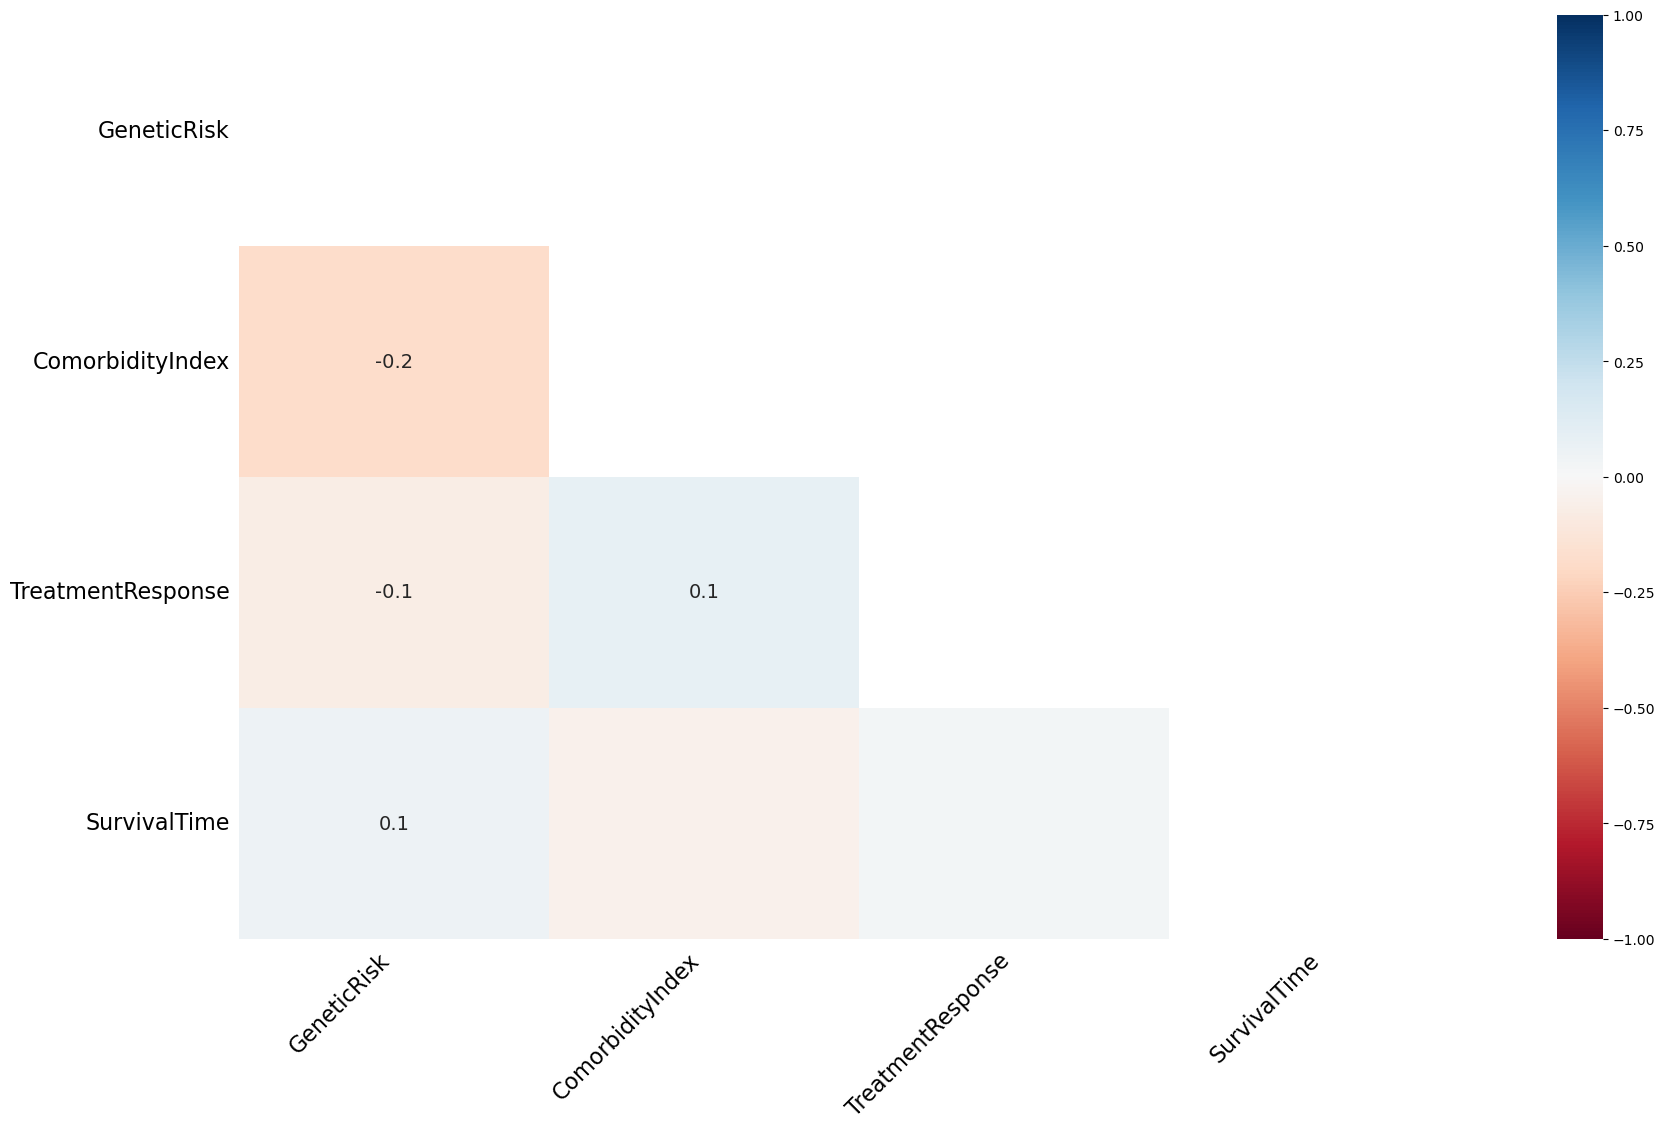

In [31]:
msno.heatmap(df)

<Axes: >

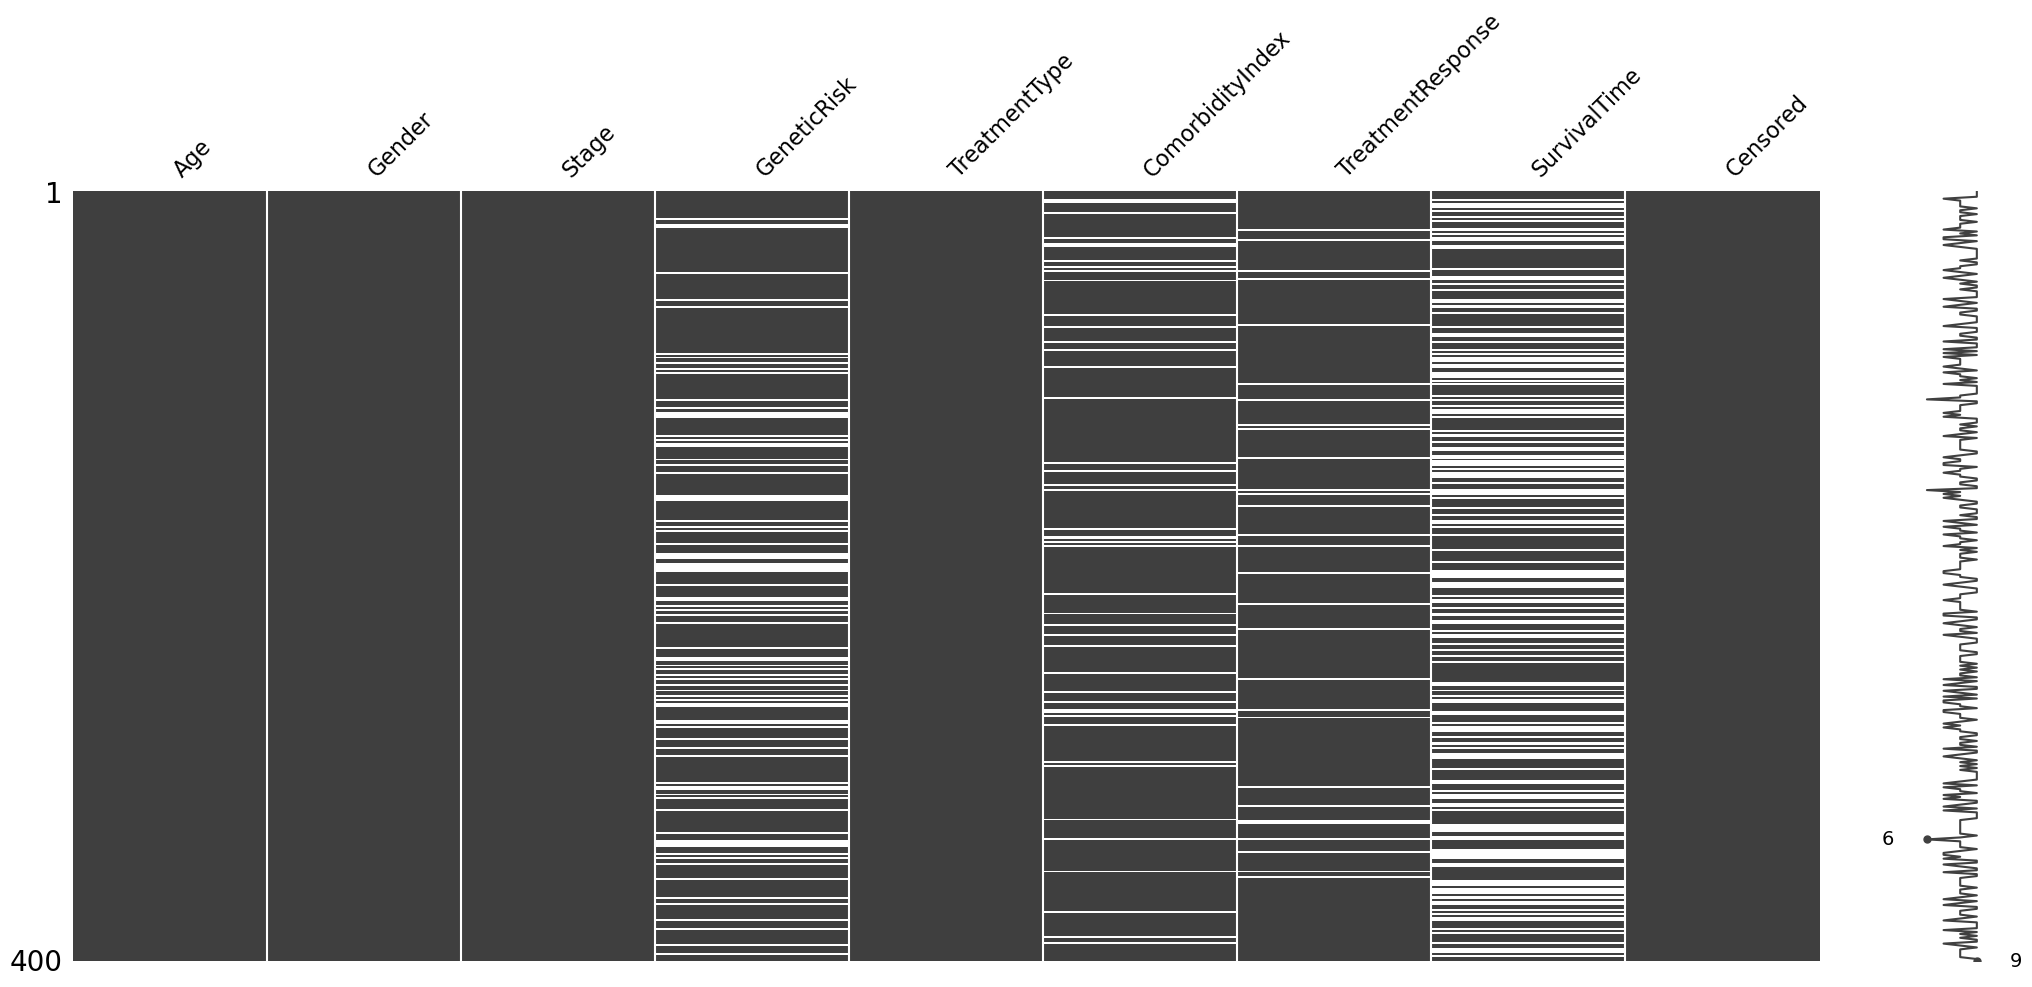

In [29]:
msno.matrix(df)

<Axes: >

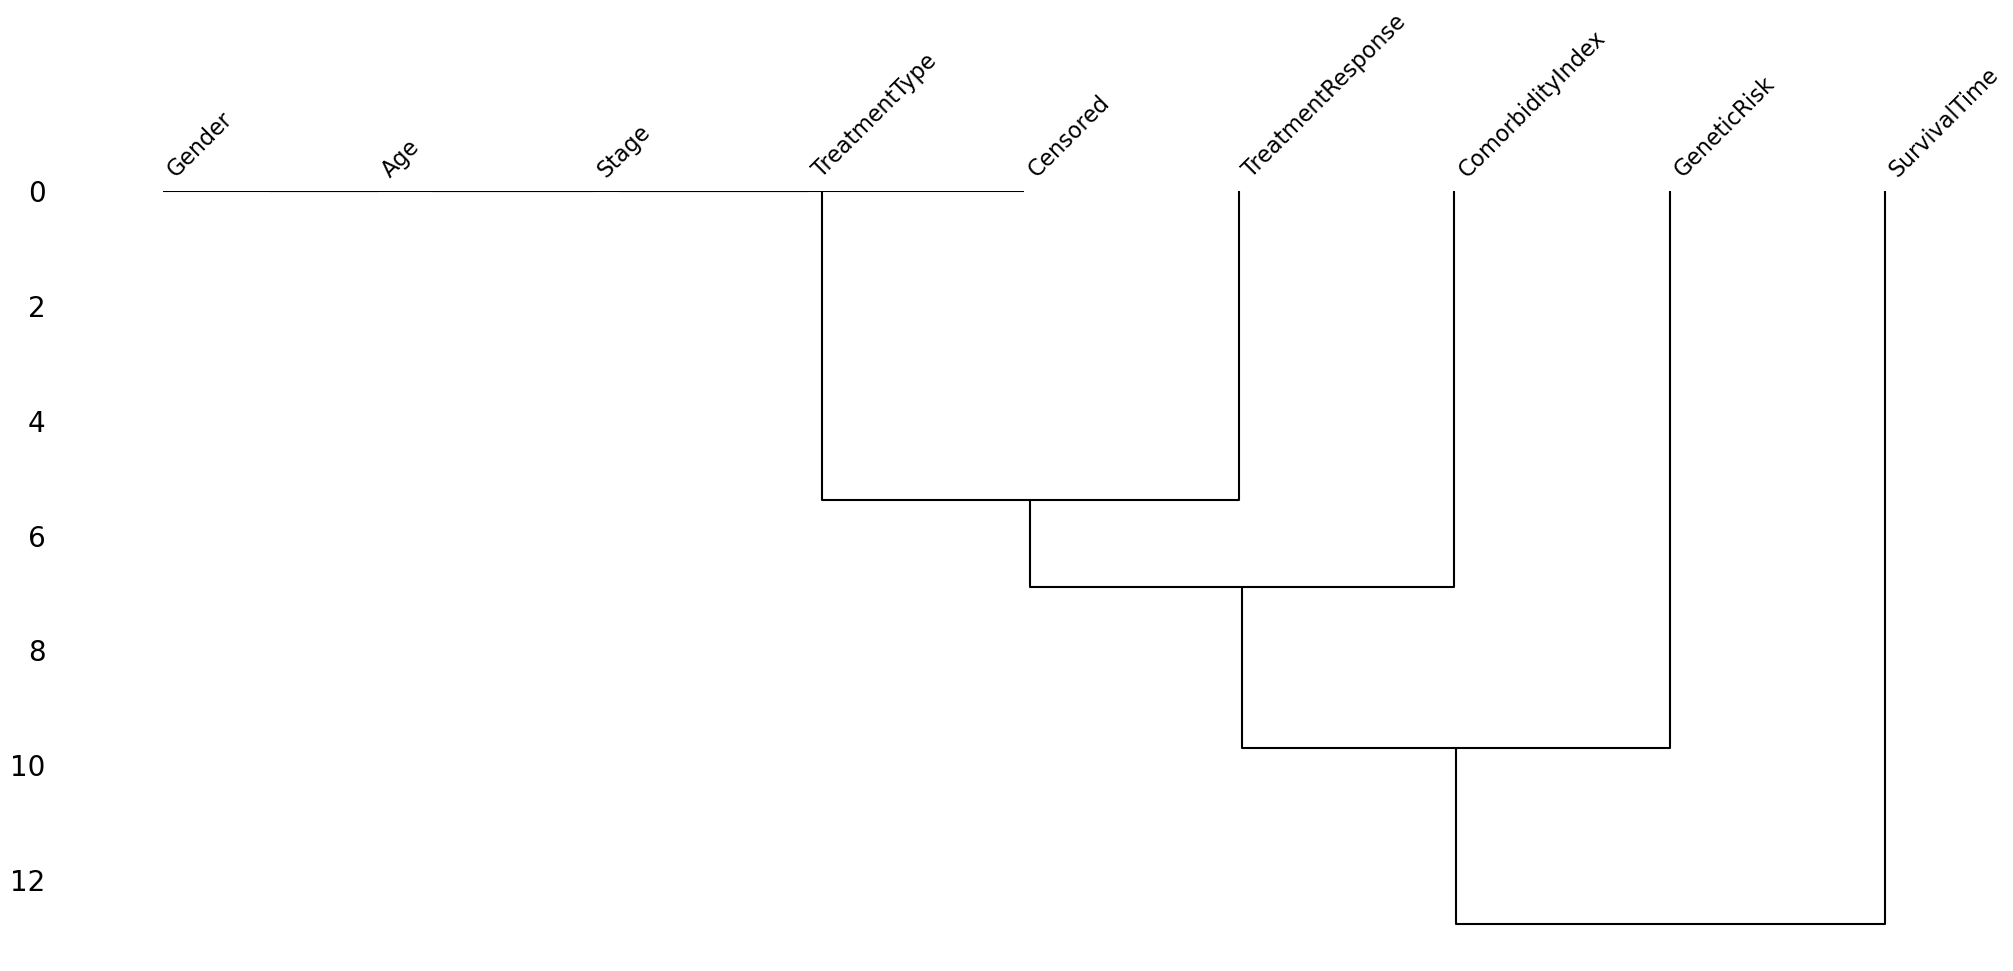

In [30]:
msno.dendrogram(df)

In [152]:
# these columns have missing data ocasionally
df.drop(columns=['GeneticRisk', 'ComorbidityIndex', 'TreatmentResponse'], inplace=True)
# drop rows with missing Survival Time or any other missing value
df = df.dropna()
# remove rows where 'Censored' is 1
df = df[df['Censored'] != 1]
print(f"Remaining points after removing censored rows: {df.shape[0]}")
df.drop(columns=['Censored'], inplace=True)
# Display the first few rows of the cleaned dataset
df.head()

Remaining points after removing censored rows: 161


,Age,Gender,Stage,TreatmentType,SurvivalTime
0,65.0,0,2,0,4.2
3,81.0,1,4,1,2.3
5,47.0,1,4,1,2.6
9,68.0,1,1,0,6.4
11,56.0,0,2,0,4.1


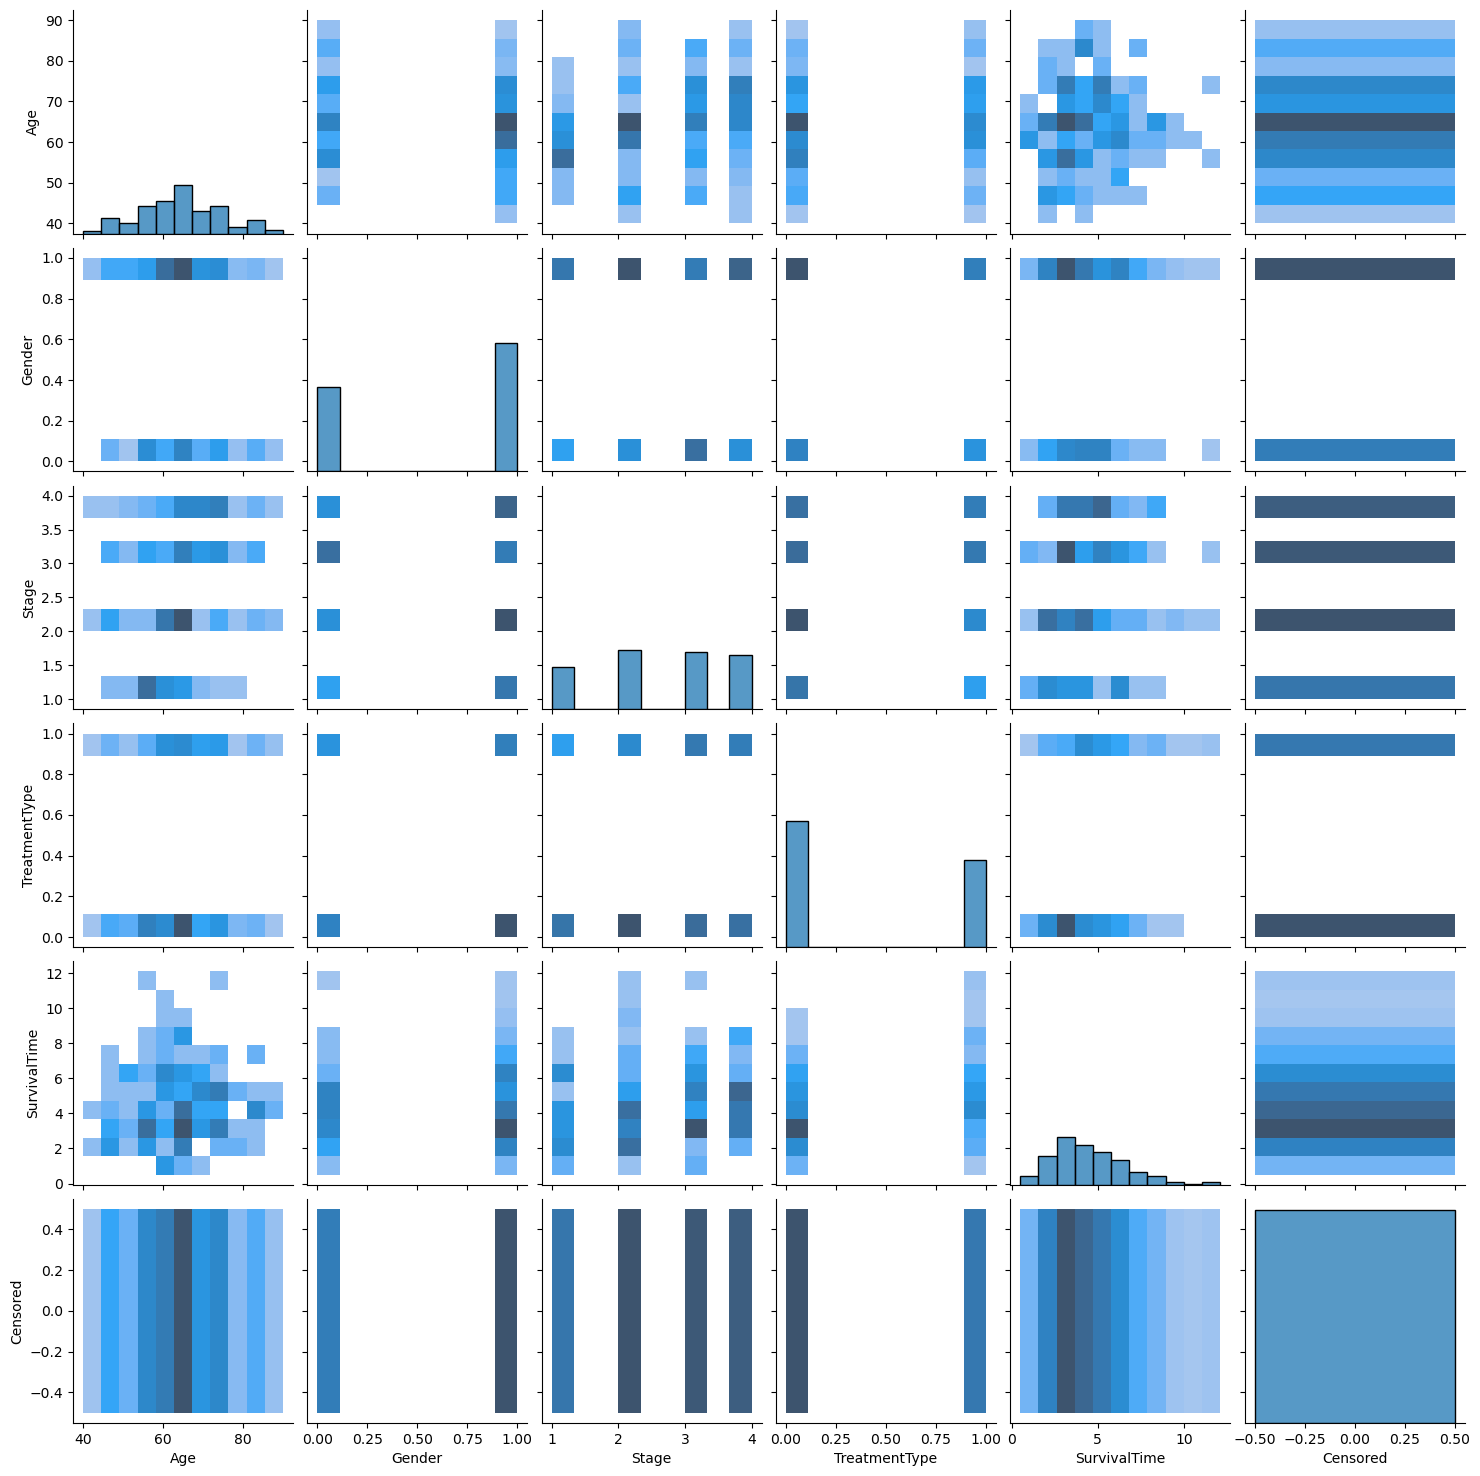

In [114]:
sns.pairplot(df, kind="hist")

In [153]:
# Define X as the feature matrix (all columns except 'SurvivalTime')
X = df.drop(columns=['SurvivalTime'])

# Define y as the target vector (SurvivalTime column)
y = df['SurvivalTime']

# Display the shapes of X and y to verify
print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape: {y.shape}")

# Optionally, display the first few rows of X and y to confirm the structure
print("Feature matrix X:")
print(X.head())

print("\nTarget vector y:")
print(y.head())


Feature matrix X shape: (161, 4)
Target vector y shape: (161,)
Feature matrix X:
     Age  Gender  Stage  TreatmentType
0   65.0       0      2              0
3   81.0       1      4              1
5   47.0       1      4              1
9   68.0       1      1              0
11  56.0       0      2              0

Target vector y:
0     4.2
3     2.3
5     2.6
9     6.4
11    4.1
Name: SurvivalTime, dtype: float64


In [154]:
# Split the data: train (80%), test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")

# Cross-validation example (5-fold)
model = LinearRegression()
cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='neg_mean_squared_error')
print(f"Cross-validation MSE scores: {-cv_scores}")
print(f"Average CV MSE: {-np.mean(cv_scores)}")

Training set size: 128
Test set size: 33
Cross-validation MSE scores: [3.10913545 3.65167699 4.18817819 5.14023426 5.47008925]
Average CV MSE: 4.311862829555013


In [155]:
# Split the data: train (80%), test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define pipeline: StandardScaler + LinearRegression
linear_reg = make_pipeline(StandardScaler(),
                            LinearRegression())

# Perform cross-validation on the training set
y_pred_cv = cross_val_predict(linear_reg, X_train, y_train, cv=10)

# Calculate cMSE for cross-validation
censored_train = np.zeros_like(y_train)  # No censored data
cMSE_cv = cMSE(y_train.values, y_pred_cv, censored_train)
print(f"Cross-Validation Censored Mean Squared Error (cMSE): {cMSE_cv}")

# Train the pipeline on the full training set
linear_reg.fit(X_train, y_train)

# Predict on the test set
y_pred_test = linear_reg.predict(X_test)

# Calculate cMSE for the test set
censored_test = np.zeros_like(y_test)  # No censored data
cMSE_test = cMSE(y_test.values, y_pred_test, censored_test)
print(f"Test Set Censored Mean Squared Error (cMSE): {cMSE_test}")

Cross-Validation Censored Mean Squared Error (cMSE): 4.3900462202941855
Test Set Censored Mean Squared Error (cMSE): 4.411178530294957


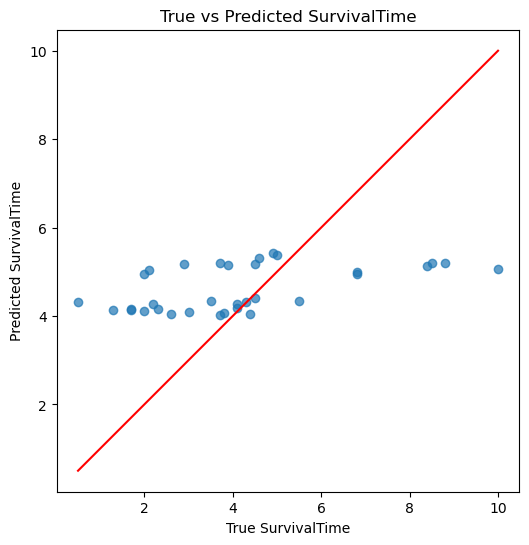

In [156]:
plot_y_yhat(y_test.values, y_pred_test, plot_title="y_yhat_plot")

In [158]:
X_kaggle_df = pd.read_csv('./mlNOVA/test_data.csv')
X_kaggle_df.drop(columns=['id'], inplace=True)
# these columns have missing data ocasionally
X_kaggle_df.drop(columns=['GeneticRisk', 'ComorbidityIndex', 'TreatmentResponse'], inplace=True)
# drop rows with missing Survival Time or any other missing value
X_kaggle_df = X_kaggle_df.dropna()
# Display the first few rows of the cleaned dataset
X_kaggle_df.head()

,Age,Gender,Stage,TreatmentType
0,71.0,1,4,1
1,57.0,1,4,0
2,66.0,0,2,0
3,73.0,0,3,1
4,53.0,1,4,0


In [159]:
y_baseline_pred = linear_reg.predict(X_kaggle_df)
save_predictions(y_baseline_pred, './submissions/baseline-submission-01.csv')